In [129]:
import requests
import pandas as pd
from bs4 import BeautifulSoup
from shapely.geometry import Point
import geopandas
import matplotlib.pyplot as plt

## ELAR

In [214]:
glottolog_data

,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,3adt1234,3Ad-Tekles,NaN,dialect,Africa,NaN,NaN
1,aala1237,Aalawa,NaN,dialect,Papunesia,NaN,NaN
2,aant1238,Aantantara,NaN,dialect,Papunesia,NaN,NaN
3,aari1239,Aari,aiw,language,Africa,5.95034,36.5721
4,aari1240,Aariya,aay,language,Eurasia,NaN,NaN
...,...,...,...,...,...,...,...
22106,zuwa1238,Zuwadza,NaN,dialect,Papunesia,NaN,NaN
22107,zwal1238,Zwall,NaN,dialect,Africa,NaN,NaN
22108,zyph1238,Zyphe,zyp,language,Eurasia,22.52400,93.2640
22109,zyud1238,Zyuzdin,NaN,dialect,Eurasia,NaN,NaN


In [120]:
ELAR_archive = 'https://www.elararchive.org/uncategorized/SO_5f038640-311d-4296-a3e9-502e8a18f5b7/'

In [121]:
html_content = requests.get(ELAR_archive).text

soup = BeautifulSoup(html_content, 'html.parser')

# Find all <p> tags with class="facet-title" and title="Language"
facet_titles = soup.find_all('div', class_='facet-group')
language_facets = [facet for facet in facet_titles if 'language' in facet.get('facet-name', '')]

elar_covered_langs_list = []

    # Loop through each language facet title to find its associated <ul> tag
for facet_title in language_facets:
    # Find the <fieldset> tag within this <p> tag
    fieldset_tag = facet_title.find_next('fieldset')
    
    if fieldset_tag:
        # Find all <input> tags within this <fieldset> tag
        input_tags = fieldset_tag.find_all('input')
        # Extract and store ids
        ids = [input_tag.get('id') for input_tag in input_tags]
        elar_covered_langs_list.extend(ids)

In [116]:
len(elar_covered_langs_list)

100

# Elar + Glottolog

In [123]:
elar_glottolog_df =  glottolog_data[glottolog_data['name'].isin(elar_covered_langs_list)]

In [124]:
len(elar_glottolog_df)

54

In [125]:
elar_glottolog_df_clean = elar_glottolog_df.dropna(subset = ['latitude', 'longitude'])

# map elar

In [118]:
points = elar_glottolog_df_clean.apply(lambda r: Point(r.longitude, r.latitude), axis=1)
gdb = geopandas.GeoDataFrame(elar_glottolog_df_clean.assign(geometry=points), \
                        crs={'init' :'epsg:4326'})
xys = gdb['geometry'].apply(lambda pt: pd.Series({'x': pt.x, 'y': pt.y}))
gdb['x'] = xys['x']
gdb['y'] = xys['y']

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


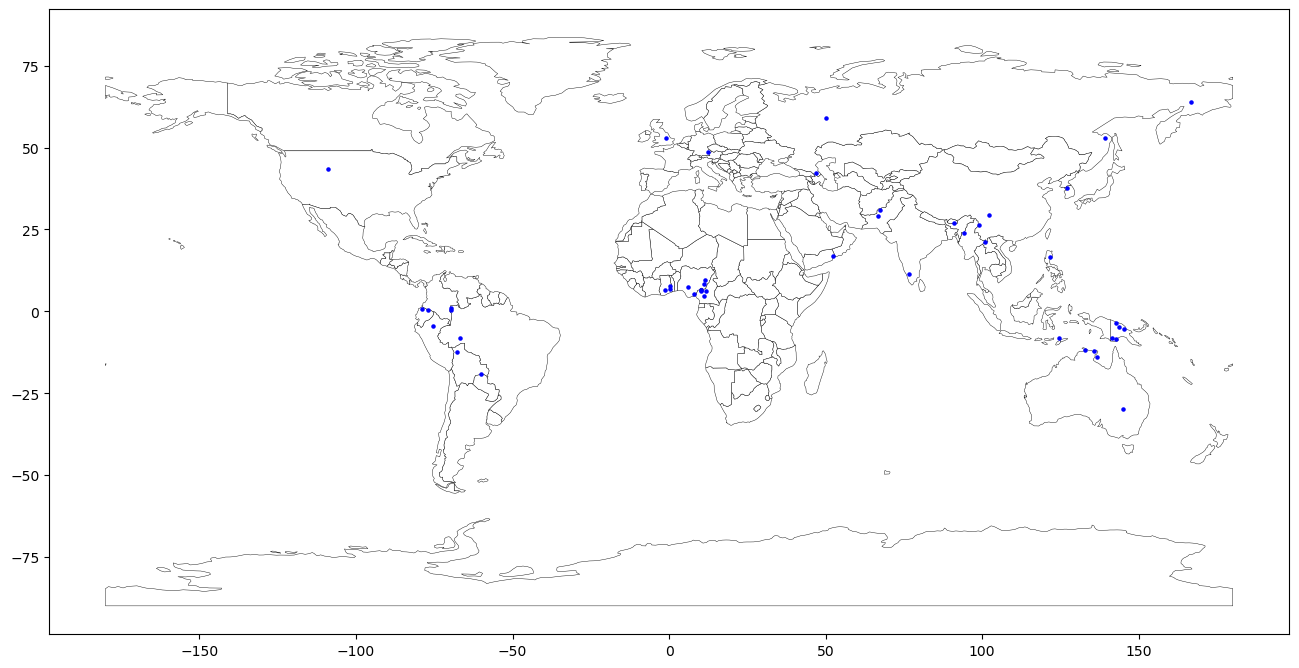

In [119]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

## ELAN

In [23]:
with open("elan.html", "r", encoding="utf-8") as file:
    elan_ul = file.read()

In [38]:
# Parse the HTML content
soup = BeautifulSoup(elan_ul, "html.parser")

# Find all <li> tags
li_tags = soup.find_all("li")

# Initialize lists to store data
names = []
hrefs = []
counts = []

# Extract name, href, and count from each <li> tag
for li in li_tags:
    a_tag = li.find("a")
    if a_tag:
        name = a_tag.get_text(strip=True)
        href = "https://archive.mpi.nl" + a_tag["href"]
        count = int(li.find("span", class_="count").get_text(strip=True).strip("()"))
        names.append(name)
        hrefs.append(href)
        counts.append(count)

# Create a DataFrame
df_elan = pd.DataFrame({"Name": names, "Href": hrefs, "Count": counts})

print(df_elan)

                                         Name  \
0                          Jakarta Indonesian   
1           Jakarta Indonesian Child Language   
2                       Turkish Sign Language   
3    Jakarta Indonesian Child-Directed Speech   
4                             infant babbling   
..                                        ...   
785           Zapotec, Santa Maria Albarradas   
786              Zapotec, Santiago Lachiguiri   
787                      Zapotec, Suchixtepec   
788                     Zapotec, Tabaa Elodia   
789                            Zapotec, Talea   

                                                  Href  Count  
0    https://archive.mpi.nl/tla/islandora/object/la...   1409  
1    https://archive.mpi.nl/tla/islandora/object/la...   1338  
2    https://archive.mpi.nl/tla/islandora/object/la...   1232  
3    https://archive.mpi.nl/tla/islandora/object/la...   1183  
4    https://archive.mpi.nl/tla/islandora/object/la...   1157  
..                         

In [42]:
def process_name(name):
    tokens = name.split(',', 1)  # Split at most once
    if len(tokens) > 1:
        return tokens[0].strip()  # Strip leading and trailing whitespace
    else:
        return name

In [175]:
df_elan['alt_name'] = df_elan['Name'].str.replace(',', '')

In [177]:
df_elan_collapsed_alt = df_elan.groupby('alt_name', as_index=False).sum()

In [178]:
df_elan_collapsed_alt

,alt_name,Name,Href,Count,short_name
0,!Xoon,!Xoon,https://archive.mpi.nl/tla/islandora/object/la...,174,!Xoon
1,!Xu,!Xu,https://archive.mpi.nl/tla/islandora/object/la...,1,!Xu
2,'N|ohan,'N|ohan,https://archive.mpi.nl/tla/islandora/object/la...,196,'N|ohan
3,=/Hoan,=/Hoan,https://archive.mpi.nl/tla/islandora/object/la...,1,=/Hoan
4,Abui,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui
...,...,...,...,...,...
784,Zapotec Texmelucan,"Zapotec, Texmelucan",https://archive.mpi.nl/tla/islandora/object/la...,2,Zapotec
785,Zapotec Totomachapan,"Zapotec, Totomachapan",https://archive.mpi.nl/tla/islandora/object/la...,2,Zapotec
786,english,english,https://archive.mpi.nl/tla/islandora/object/la...,3,english
787,infant babbling,infant babbling,https://archive.mpi.nl/tla/islandora/object/la...,1157,infant babbling


In [43]:
df_elan['short_name'] = df_elan['Name'].apply(process_name)

In [88]:
df_elan

,Name,Href,Count,short_name
0,Jakarta Indonesian,https://archive.mpi.nl/tla/islandora/object/la...,1409,Jakarta Indonesian
1,Jakarta Indonesian Child Language,https://archive.mpi.nl/tla/islandora/object/la...,1338,Jakarta Indonesian Child Language
2,Turkish Sign Language,https://archive.mpi.nl/tla/islandora/object/la...,1232,Turkish Sign Language
3,Jakarta Indonesian Child-Directed Speech,https://archive.mpi.nl/tla/islandora/object/la...,1183,Jakarta Indonesian Child-Directed Speech
4,infant babbling,https://archive.mpi.nl/tla/islandora/object/la...,1157,infant babbling
...,...,...,...,...
785,"Zapotec, Santa Maria Albarradas",https://archive.mpi.nl/tla/islandora/object/la...,1,Zapotec
786,"Zapotec, Santiago Lachiguiri",https://archive.mpi.nl/tla/islandora/object/la...,1,Zapotec
787,"Zapotec, Suchixtepec",https://archive.mpi.nl/tla/islandora/object/la...,1,Zapotec
788,"Zapotec, Tabaa Elodia",https://archive.mpi.nl/tla/islandora/object/la...,1,Zapotec


In [126]:
abui_index_number = df_elan.loc[df_elan['short_name'] == 'Abui'].index[0]

In [127]:
abui_index_number

52

In [89]:
df_elan_collapsed = df_elan.groupby('short_name', as_index=False).sum()

In [90]:
df_elan_collapsed

,short_name,Name,Href,Count
0,!Xoon,!Xoon,https://archive.mpi.nl/tla/islandora/object/la...,174
1,!Xu,!Xu,https://archive.mpi.nl/tla/islandora/object/la...,1
2,'N|ohan,'N|ohan,https://archive.mpi.nl/tla/islandora/object/la...,196
3,=/Hoan,=/Hoan,https://archive.mpi.nl/tla/islandora/object/la...,1
4,Abui,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248
...,...,...,...,...
611,Yuracare,Yuracare,https://archive.mpi.nl/tla/islandora/object/la...,7
612,Zapotec,"Zapotec, AtepecZapotec, BetazaZapotec, Chichic...",https://archive.mpi.nl/tla/islandora/object/la...,82
613,english,english,https://archive.mpi.nl/tla/islandora/object/la...,3
614,infant babbling,infant babbling,https://archive.mpi.nl/tla/islandora/object/la...,1157


In [82]:
df_elan_unique = df_elan.drop_duplicates(subset=['short_name'])

In [83]:
df_elan_unique

,Name,Href,Count,short_name
0,Jakarta Indonesian,https://archive.mpi.nl/tla/islandora/object/la...,1409,Jakarta Indonesian
1,Jakarta Indonesian Child Language,https://archive.mpi.nl/tla/islandora/object/la...,1338,Jakarta Indonesian Child Language
2,Turkish Sign Language,https://archive.mpi.nl/tla/islandora/object/la...,1232,Turkish Sign Language
3,Jakarta Indonesian Child-Directed Speech,https://archive.mpi.nl/tla/islandora/object/la...,1183,Jakarta Indonesian Child-Directed Speech
4,infant babbling,https://archive.mpi.nl/tla/islandora/object/la...,1157,infant babbling
...,...,...,...,...
743,"West Sumatra, Tansi",https://archive.mpi.nl/tla/islandora/object/la...,1,West Sumatra
744,Wára (Wära),https://archive.mpi.nl/tla/islandora/object/la...,1,Wára (Wära)
745,Yakut,https://archive.mpi.nl/tla/islandora/object/la...,1,Yakut
746,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití


In [170]:
abui_index_number = df_elan_unique.loc[df_elan_unique['short_name'] == 'Zapotec']

In [171]:
abui_index_number

,Name,Href,Count,short_name
483,"Zapotec, Atepec",https://archive.mpi.nl/tla/islandora/object/la...,2,Zapotec


In [169]:
df_elan_unique[480:485]

,Name,Href,Count,short_name
556,Dengka,https://archive.mpi.nl/tla/islandora/object/la...,1,Dengka
557,"Desa (Meliau), Beopay dialect",https://archive.mpi.nl/tla/islandora/object/la...,1,Desa (Meliau)
558,East !Xoon,https://archive.mpi.nl/tla/islandora/object/la...,1,East !Xoon
559,"Farsi, Western",https://archive.mpi.nl/tla/islandora/object/la...,1,Farsi
560,Fataluku,https://archive.mpi.nl/tla/islandora/object/la...,1,Fataluku


## DOBES

In [28]:
with open("dobes.html", "r", encoding="utf-8") as file:
    dobes_ul = file.read()

In [131]:
# Parse the HTML content
dobes_soup = BeautifulSoup(dobes_ul, "html.parser")

# Find all <li> tags
li_tags = dobes_soup.find_all("li")

# Initialize lists to store data
names = []
hrefs = []
counts = []

# Extract name, href, and count from each <li> tag
for li in li_tags:
    a_tag = li.find("a")
    if a_tag:
        name = a_tag.get_text(strip=True)
        href = "https://archive.mpi.nl" + a_tag["href"]
        count = int(li.find("span", class_="count").get_text(strip=True).strip("()"))
        names.append(name)
        hrefs.append(href)
        counts.append(count)

# Create a DataFrame
dobes_df = pd.DataFrame({"Name": names, "Href": hrefs, "Count": counts})

In [132]:
dobes_df

,Name,Href,Count
0,English,https://archive.mpi.nl/tla/islandora/object/tl...,2883
1,Spanish,https://archive.mpi.nl/tla/islandora/object/tl...,2738
2,Yurakaré,https://archive.mpi.nl/tla/islandora/object/tl...,1645
3,Beaver,https://archive.mpi.nl/tla/islandora/object/tl...,1042
4,Portuguese,https://archive.mpi.nl/tla/islandora/object/tl...,925
...,...,...,...
301,Tzeltal,https://archive.mpi.nl/tla/islandora/object/tl...,1
302,Waurá,https://archive.mpi.nl/tla/islandora/object/tl...,1
303,Wára (Wära),https://archive.mpi.nl/tla/islandora/object/tl...,1
304,Yawalapití,https://archive.mpi.nl/tla/islandora/object/tl...,1


In [134]:
dobes_df['short_name'] = dobes_df['Name'].apply(process_name)

In [137]:
dobes_df

,Name,Href,Count,short_name
0,English,https://archive.mpi.nl/tla/islandora/object/tl...,2883,English
1,Spanish,https://archive.mpi.nl/tla/islandora/object/tl...,2738,Spanish
2,Yurakaré,https://archive.mpi.nl/tla/islandora/object/tl...,1645,Yurakaré
3,Beaver,https://archive.mpi.nl/tla/islandora/object/tl...,1042,Beaver
4,Portuguese,https://archive.mpi.nl/tla/islandora/object/tl...,925,Portuguese
...,...,...,...,...
301,Tzeltal,https://archive.mpi.nl/tla/islandora/object/tl...,1,Tzeltal
302,Waurá,https://archive.mpi.nl/tla/islandora/object/tl...,1,Waurá
303,Wára (Wära),https://archive.mpi.nl/tla/islandora/object/tl...,1,Wára (Wära)
304,Yawalapití,https://archive.mpi.nl/tla/islandora/object/tl...,1,Yawalapití


In [138]:
dobes_merge = pd.merge(dobes_df, glottolog_data, left_on='short_name', right_on='name', how = 'inner')

In [139]:
dobes_merge

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,English,https://archive.mpi.nl/tla/islandora/object/tl...,2883,English,stan1293,English,eng,language,Eurasia,53.000000,-1.000000
1,Spanish,https://archive.mpi.nl/tla/islandora/object/tl...,2738,Spanish,stan1288,Spanish,spa,language,Eurasia,40.441400,-1.117880
2,Beaver,https://archive.mpi.nl/tla/islandora/object/tl...,1042,Beaver,beav1236,Beaver,bea,language,North America,56.798400,-120.352000
3,Portuguese,https://archive.mpi.nl/tla/islandora/object/tl...,925,Portuguese,port1283,Portuguese,por,language,Eurasia,39.910000,-8.100000
4,Bora,https://archive.mpi.nl/tla/islandora/object/tl...,701,Bora,bora1263,Bora,boa,language,South America,-2.000259,-72.257066
...,...,...,...,...,...,...,...,...,...,...,...
126,"Tibetan, Amdo",https://archive.mpi.nl/tla/islandora/object/tl...,1,Tibetan,tibe1272,Tibetan,bod,language,Eurasia,28.368100,90.187200
127,Toba,https://archive.mpi.nl/tla/islandora/object/tl...,1,Toba,toba1269,Toba,tob,language,South America,-23.770000,-61.960000
128,Tzeltal,https://archive.mpi.nl/tla/islandora/object/tl...,1,Tzeltal,tzel1254,Tzeltal,tzh,language,North America,16.638400,-92.278600
129,Waurá,https://archive.mpi.nl/tla/islandora/object/tl...,1,Waurá,waur1244,Waurá,wau,language,South America,-13.296000,-53.697100


# Attempt Glottolog merge...

In [31]:
glottolog_data = pd.read_csv('languages_and_dialects_geo.csv')

In [49]:
elan_merge = pd.merge(df_elan_unique, glottolog_data, left_on='short_name', right_on='name', how = 'inner')

In [50]:
elan_merge

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Turkish Sign Language,https://archive.mpi.nl/tla/islandora/object/la...,1232,Turkish Sign Language,turk1288,Turkish Sign Language,tsm,language,Eurasia,41.026750,28.85551
1,Beaver,https://archive.mpi.nl/tla/islandora/object/la...,1042,Beaver,beav1236,Beaver,bea,language,North America,56.798400,-120.35200
2,Kilivila,https://archive.mpi.nl/tla/islandora/object/la...,1037,Kilivila,kili1267,Kilivila,kij,language,Papunesia,-8.725740,151.07200
3,Portuguese,https://archive.mpi.nl/tla/islandora/object/la...,935,Portuguese,port1283,Portuguese,por,language,Eurasia,39.910000,-8.10000
4,Czech,https://archive.mpi.nl/tla/islandora/object/la...,909,Czech,czec1258,Czech,ces,language,Eurasia,49.873398,15.10437
...,...,...,...,...,...,...,...,...,...,...,...
264,Waurá,https://archive.mpi.nl/tla/islandora/object/la...,1,Waurá,waur1244,Waurá,wau,language,South America,-13.296000,-53.69710
265,Wersing,https://archive.mpi.nl/tla/islandora/object/la...,1,Wersing,wers1238,Wersing,kvw,language,Papunesia,-8.339360,124.93200
266,West Javanese,https://archive.mpi.nl/tla/islandora/object/la...,1,West Javanese,west2565,West Javanese,NaN,dialect,Papunesia,NaN,NaN
267,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití,yawa1261,Yawalapití,yaw,language,South America,-12.510400,-53.42360


In [53]:
elan_merge = elan_merge.dropna(subset = ['latitude', 'longitude'])

In [54]:
elan_merge

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Turkish Sign Language,https://archive.mpi.nl/tla/islandora/object/la...,1232,Turkish Sign Language,turk1288,Turkish Sign Language,tsm,language,Eurasia,41.026750,28.85551
1,Beaver,https://archive.mpi.nl/tla/islandora/object/la...,1042,Beaver,beav1236,Beaver,bea,language,North America,56.798400,-120.35200
2,Kilivila,https://archive.mpi.nl/tla/islandora/object/la...,1037,Kilivila,kili1267,Kilivila,kij,language,Papunesia,-8.725740,151.07200
3,Portuguese,https://archive.mpi.nl/tla/islandora/object/la...,935,Portuguese,port1283,Portuguese,por,language,Eurasia,39.910000,-8.10000
4,Czech,https://archive.mpi.nl/tla/islandora/object/la...,909,Czech,czec1258,Czech,ces,language,Eurasia,49.873398,15.10437
...,...,...,...,...,...,...,...,...,...,...,...
263,Wambon,https://archive.mpi.nl/tla/islandora/object/la...,1,Wambon,wamb1259,Wambon,wms,language,Papunesia,-5.443340,140.48000
264,Waurá,https://archive.mpi.nl/tla/islandora/object/la...,1,Waurá,waur1244,Waurá,wau,language,South America,-13.296000,-53.69710
265,Wersing,https://archive.mpi.nl/tla/islandora/object/la...,1,Wersing,wers1238,Wersing,kvw,language,Papunesia,-8.339360,124.93200
267,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití,yawa1261,Yawalapití,yaw,language,South America,-12.510400,-53.42360


In [56]:
points = elan_merge.apply(lambda r: Point(r.longitude, r.latitude), axis=1)
gdb = geopandas.GeoDataFrame(elan_merge.assign(geometry=points), \
                        crs={'init' :'epsg:4326'})
xys = gdb['geometry'].apply(lambda pt: pd.Series({'x': pt.x, 'y': pt.y}))
gdb['x'] = xys['x']
gdb['y'] = xys['y']

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [61]:
worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_45368/867032107.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  worldmap = geopandas.read_file(geopandas.datasets.get_path("naturalearth_lowres"))


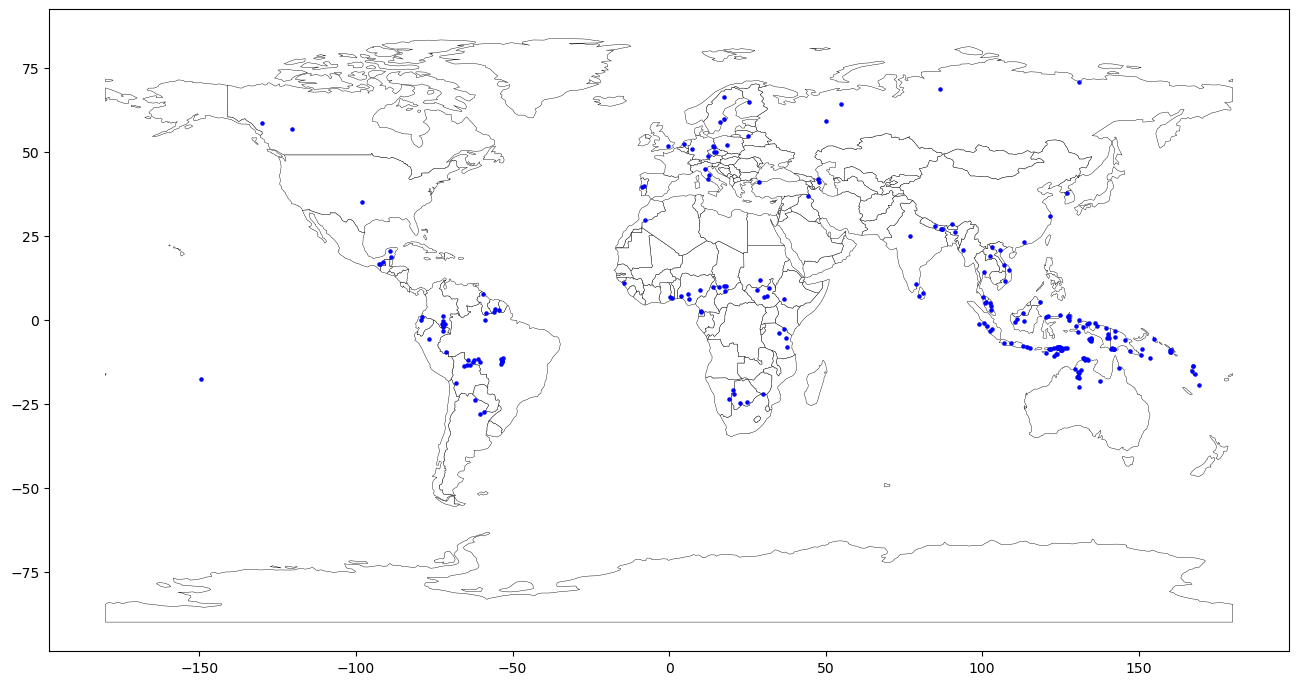

In [62]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

In [140]:
elan_dobas_merge = pd.merge(elan_merge, dobes_merge, how = 'outer')

In [141]:
elan_dobas_merge

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
1,Adang,https://archive.mpi.nl/tla/islandora/object/la...,61,Adang,adan1251,Adang,adn,language,Papunesia,-8.18958,124.44800
2,Afrikaans,https://archive.mpi.nl/tla/islandora/object/la...,377,Afrikaans,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
3,Afrikaans,https://archive.mpi.nl/tla/islandora/object/tl...,377,Afrikaans,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
4,Aikanã,https://archive.mpi.nl/tla/islandora/object/la...,374,Aikanã,aika1237,Aikanã,tba,language,South America,-12.66950,-60.53530
...,...,...,...,...,...,...,...,...,...,...,...
364,Yeri,https://archive.mpi.nl/tla/islandora/object/la...,245,Yeri,yapu1240,Yeri,yev,language,Papunesia,-3.47256,142.43600
365,Yoruba,https://archive.mpi.nl/tla/islandora/object/la...,2,Yoruba,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
366,Yoruba,https://archive.mpi.nl/tla/islandora/object/tl...,2,Yoruba,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
367,Yucatec Maya,https://archive.mpi.nl/tla/islandora/object/la...,8,Yucatec Maya,yuca1254,Yucatec Maya,yua,language,North America,18.77570,-88.95670


In [142]:
df_unique = elan_dobas_merge.drop_duplicates(subset=['Name'], keep='first')

print(df_unique)

                           Name  \
0                          Abui   
1                         Adang   
2                     Afrikaans   
4                        Aikanã   
6                          Akie   
..                          ...   
362                  Yawalapití   
364                        Yeri   
365                      Yoruba   
367                Yucatec Maya   
368  Yucatec Maya Sign Language   

                                                  Href  Count  \
0    https://archive.mpi.nl/tla/islandora/object/la...    248   
1    https://archive.mpi.nl/tla/islandora/object/la...     61   
2    https://archive.mpi.nl/tla/islandora/object/la...    377   
4    https://archive.mpi.nl/tla/islandora/object/la...    374   
6    https://archive.mpi.nl/tla/islandora/object/la...    181   
..                                                 ...    ...   
362  https://archive.mpi.nl/tla/islandora/object/la...      1   
364  https://archive.mpi.nl/tla/islandora/object/la...    2

In [143]:
df_unique

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
1,Adang,https://archive.mpi.nl/tla/islandora/object/la...,61,Adang,adan1251,Adang,adn,language,Papunesia,-8.18958,124.44800
2,Afrikaans,https://archive.mpi.nl/tla/islandora/object/la...,377,Afrikaans,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
4,Aikanã,https://archive.mpi.nl/tla/islandora/object/la...,374,Aikanã,aika1237,Aikanã,tba,language,South America,-12.66950,-60.53530
6,Akie,https://archive.mpi.nl/tla/islandora/object/la...,181,Akie,mosi1247,Akie,mwy,language,Africa,-5.43471,37.18690
...,...,...,...,...,...,...,...,...,...,...,...
362,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití,yawa1261,Yawalapití,yaw,language,South America,-12.51040,-53.42360
364,Yeri,https://archive.mpi.nl/tla/islandora/object/la...,245,Yeri,yapu1240,Yeri,yev,language,Papunesia,-3.47256,142.43600
365,Yoruba,https://archive.mpi.nl/tla/islandora/object/la...,2,Yoruba,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
367,Yucatec Maya,https://archive.mpi.nl/tla/islandora/object/la...,8,Yucatec Maya,yuca1254,Yucatec Maya,yua,language,North America,18.77570,-88.95670


In [144]:
points = df_unique.apply(lambda r: Point(r.longitude, r.latitude), axis=1)
gdb = geopandas.GeoDataFrame(df_unique.assign(geometry=points), \
                        crs={'init' :'epsg:4326'})
xys = gdb['geometry'].apply(lambda pt: pd.Series({'x': pt.x, 'y': pt.y}))
gdb['x'] = xys['x']
gdb['y'] = xys['y']

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


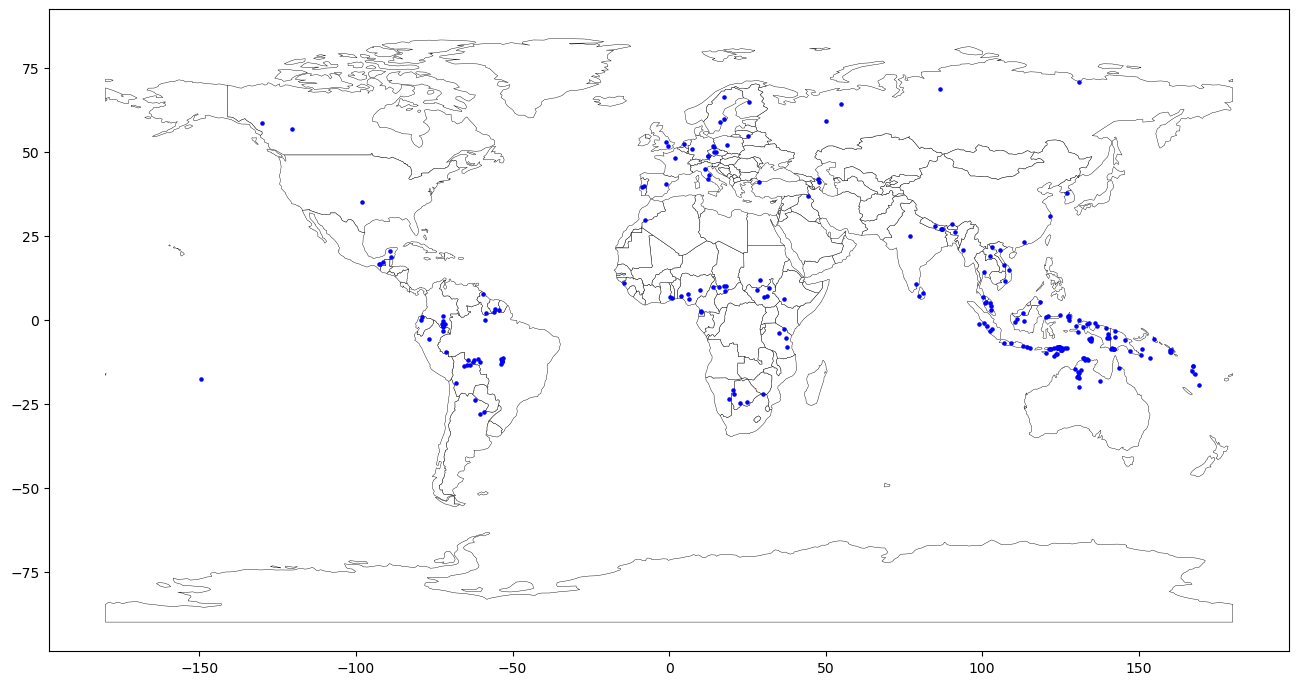

In [145]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

# Compare ELAR and ELAN

In [102]:
df_unique

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
1,Adang,https://archive.mpi.nl/tla/islandora/object/la...,61,Adang,adan1251,Adang,adn,language,Papunesia,-8.18958,124.44800
2,Afrikaans,https://archive.mpi.nl/tla/islandora/object/la...,377,Afrikaans,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
4,Aikanã,https://archive.mpi.nl/tla/islandora/object/la...,374,Aikanã,aika1237,Aikanã,tba,language,South America,-12.66950,-60.53530
6,Akie,https://archive.mpi.nl/tla/islandora/object/la...,181,Akie,mosi1247,Akie,mwy,language,Africa,-5.43471,37.18690
...,...,...,...,...,...,...,...,...,...,...,...
359,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití,yawa1261,Yawalapití,yaw,language,South America,-12.51040,-53.42360
361,Yeri,https://archive.mpi.nl/tla/islandora/object/la...,245,Yeri,yapu1240,Yeri,yev,language,Papunesia,-3.47256,142.43600
362,Yoruba,https://archive.mpi.nl/tla/islandora/object/la...,2,Yoruba,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
364,Yucatec Maya,https://archive.mpi.nl/tla/islandora/object/la...,8,Yucatec Maya,yuca1254,Yucatec Maya,yua,language,North America,18.77570,-88.95670


In [104]:
merge_elan_elar =  df_unique[df_unique['short_name'].isin(elar_covered_langs_list)]

In [105]:
merge_elan_elar

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
12,Amurdak,https://archive.mpi.nl/tla/islandora/object/la...,3,Amurdak,amar1271,Amurdak,amg,language,Australia,-11.98760,132.87800
17,Arammba,https://archive.mpi.nl/tla/islandora/object/la...,5,Arammba,aram1253,Arammba,stk,language,Papunesia,-8.29593,141.44500
22,Avatime,https://archive.mpi.nl/tla/islandora/object/la...,439,Avatime,avat1244,Avatime,avn,language,Africa,6.86880,0.41314
56,Cha'palaa,https://archive.mpi.nl/tla/islandora/object/la...,78,Cha'palaa,chac1249,Cha'palaa,cbi,language,South America,0.71489,-79.05080
89,"German, Standard",https://archive.mpi.nl/tla/islandora/object/la...,2,German,stan1295,German,deu,language,Eurasia,48.64900,12.46760
152,Korean,https://archive.mpi.nl/tla/islandora/object/la...,1,Korean,kore1280,Korean,kor,language,Eurasia,37.54000,126.98000
250,Russian,https://archive.mpi.nl/tla/islandora/object/la...,293,Russian,russ1263,Russian,rus,language,Eurasia,59.00000,50.00000


In [106]:
diff_elan_elar =  df_unique[~df_unique['short_name'].isin(elar_covered_langs_list)]

In [107]:
diff_elan_elar

,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
1,Adang,https://archive.mpi.nl/tla/islandora/object/la...,61,Adang,adan1251,Adang,adn,language,Papunesia,-8.18958,124.44800
2,Afrikaans,https://archive.mpi.nl/tla/islandora/object/la...,377,Afrikaans,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
4,Aikanã,https://archive.mpi.nl/tla/islandora/object/la...,374,Aikanã,aika1237,Aikanã,tba,language,South America,-12.66950,-60.53530
6,Akie,https://archive.mpi.nl/tla/islandora/object/la...,181,Akie,mosi1247,Akie,mwy,language,Africa,-5.43471,37.18690
8,Akurio,https://archive.mpi.nl/tla/islandora/object/la...,4,Akurio,akur1238,Akurio,ako,language,South America,3.19607,-55.62940
...,...,...,...,...,...,...,...,...,...,...,...
359,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití,yawa1261,Yawalapití,yaw,language,South America,-12.51040,-53.42360
361,Yeri,https://archive.mpi.nl/tla/islandora/object/la...,245,Yeri,yapu1240,Yeri,yev,language,Papunesia,-3.47256,142.43600
362,Yoruba,https://archive.mpi.nl/tla/islandora/object/la...,2,Yoruba,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
364,Yucatec Maya,https://archive.mpi.nl/tla/islandora/object/la...,8,Yucatec Maya,yuca1254,Yucatec Maya,yua,language,North America,18.77570,-88.95670


# Map resource number

In [146]:
df_elan_collapsed

,short_name,Name,Href,Count
0,!Xoon,!Xoon,https://archive.mpi.nl/tla/islandora/object/la...,174
1,!Xu,!Xu,https://archive.mpi.nl/tla/islandora/object/la...,1
2,'N|ohan,'N|ohan,https://archive.mpi.nl/tla/islandora/object/la...,196
3,=/Hoan,=/Hoan,https://archive.mpi.nl/tla/islandora/object/la...,1
4,Abui,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248
...,...,...,...,...
611,Yuracare,Yuracare,https://archive.mpi.nl/tla/islandora/object/la...,7
612,Zapotec,"Zapotec, AtepecZapotec, BetazaZapotec, Chichic...",https://archive.mpi.nl/tla/islandora/object/la...,82
613,english,english,https://archive.mpi.nl/tla/islandora/object/la...,3
614,infant babbling,infant babbling,https://archive.mpi.nl/tla/islandora/object/la...,1157


In [147]:
df_elan_collapsed = df_elan.groupby('short_name', as_index=False).sum()

In [148]:
elan_collapsed_merge = pd.merge(df_elan_collapsed, glottolog_data, left_on='short_name', right_on='name', how = 'inner')

In [149]:
elan_collapsed_merge

,short_name,Name,Href,Count,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Abui,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
1,Adang,Adang,https://archive.mpi.nl/tla/islandora/object/la...,61,adan1251,Adang,adn,language,Papunesia,-8.18958,124.44800
2,Afrikaans,Afrikaans,https://archive.mpi.nl/tla/islandora/object/la...,377,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
3,Aikanã,Aikanã,https://archive.mpi.nl/tla/islandora/object/la...,374,aika1237,Aikanã,tba,language,South America,-12.66950,-60.53530
4,Akie,Akie,https://archive.mpi.nl/tla/islandora/object/la...,181,mosi1247,Akie,mwy,language,Africa,-5.43471,37.18690
...,...,...,...,...,...,...,...,...,...,...,...
264,Yawalapití,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,yawa1261,Yawalapití,yaw,language,South America,-12.51040,-53.42360
265,Yeri,Yeri,https://archive.mpi.nl/tla/islandora/object/la...,245,yapu1240,Yeri,yev,language,Papunesia,-3.47256,142.43600
266,Yoruba,Yoruba,https://archive.mpi.nl/tla/islandora/object/la...,2,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
267,Yucatec Maya,Yucatec Maya,https://archive.mpi.nl/tla/islandora/object/la...,8,yuca1254,Yucatec Maya,yua,language,North America,18.77570,-88.95670


In [198]:
glottolog_data

,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,3adt1234,3Ad-Tekles,NaN,dialect,Africa,NaN,NaN
1,aala1237,Aalawa,NaN,dialect,Papunesia,NaN,NaN
2,aant1238,Aantantara,NaN,dialect,Papunesia,NaN,NaN
3,aari1239,Aari,aiw,language,Africa,5.95034,36.5721
4,aari1240,Aariya,aay,language,Eurasia,NaN,NaN
...,...,...,...,...,...,...,...
22106,zuwa1238,Zuwadza,NaN,dialect,Papunesia,NaN,NaN
22107,zwal1238,Zwall,NaN,dialect,Africa,NaN,NaN
22108,zyph1238,Zyphe,zyp,language,Eurasia,22.52400,93.2640
22109,zyud1238,Zyuzdin,NaN,dialect,Eurasia,NaN,NaN


In [ ]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
gdb.plot(ax=ax, color = 'blue', markersize = 5)
plt.show()

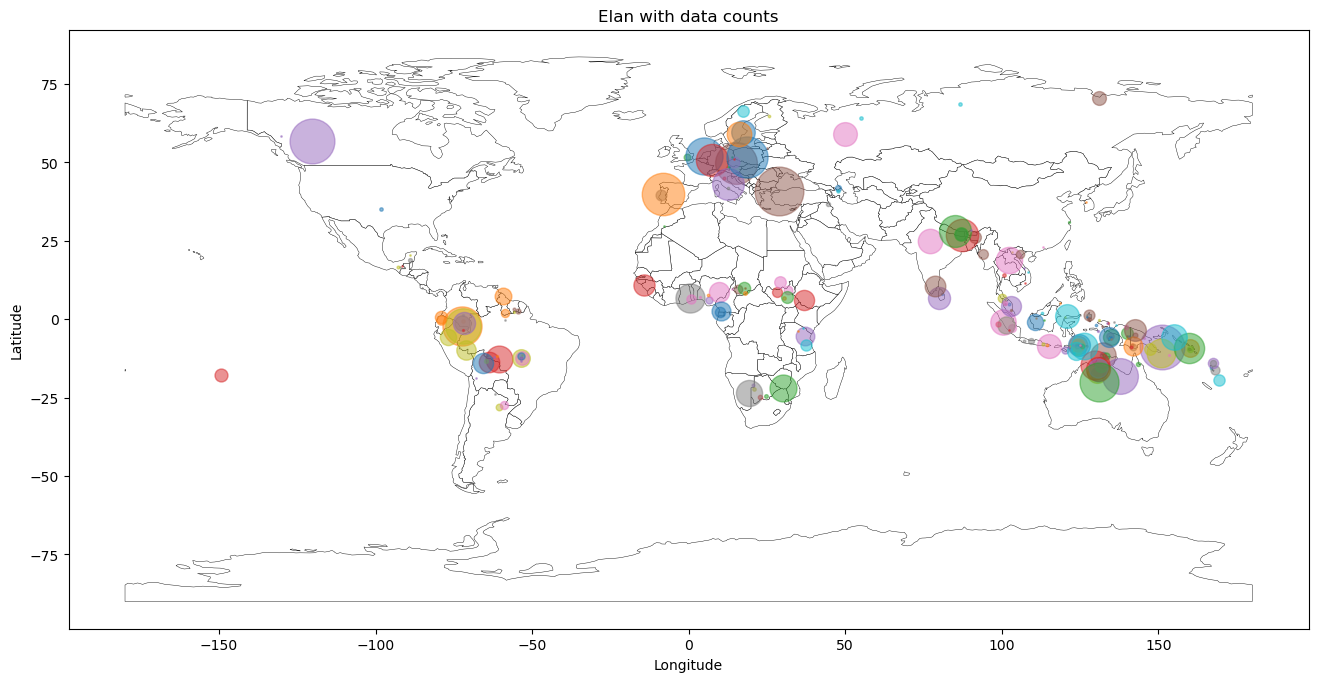

In [165]:
fig, ax = plt.subplots(figsize=(16, 10))
worldmap.plot(color="white", edgecolor = 'black',ax=ax, linewidth=0.3)
plt.title('Elan with data counts')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Plot circles on the map
for index, row in elan_collapsed_merge.iterrows():
    ax.scatter(row['longitude'], row['latitude'], s=row['Count'], alpha=0.5)

# Show the plot
plt.show()



# Alt merge

In [179]:
df_elan_collapsed_alt

,alt_name,Name,Href,Count,short_name
0,!Xoon,!Xoon,https://archive.mpi.nl/tla/islandora/object/la...,174,!Xoon
1,!Xu,!Xu,https://archive.mpi.nl/tla/islandora/object/la...,1,!Xu
2,'N|ohan,'N|ohan,https://archive.mpi.nl/tla/islandora/object/la...,196,'N|ohan
3,=/Hoan,=/Hoan,https://archive.mpi.nl/tla/islandora/object/la...,1,=/Hoan
4,Abui,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui
...,...,...,...,...,...
784,Zapotec Texmelucan,"Zapotec, Texmelucan",https://archive.mpi.nl/tla/islandora/object/la...,2,Zapotec
785,Zapotec Totomachapan,"Zapotec, Totomachapan",https://archive.mpi.nl/tla/islandora/object/la...,2,Zapotec
786,english,english,https://archive.mpi.nl/tla/islandora/object/la...,3,english
787,infant babbling,infant babbling,https://archive.mpi.nl/tla/islandora/object/la...,1157,infant babbling


In [180]:
elan_collapsed_alt_merge = pd.merge(df_elan_collapsed_alt, glottolog_data, left_on='short_name', right_on='name', how = 'inner')

In [181]:
elan_collapsed_alt_merge

,alt_name,Name,Href,Count,short_name,glottocode,name,isocodes,level,macroarea,latitude,longitude
0,Abui,Abui,https://archive.mpi.nl/tla/islandora/object/la...,248,Abui,abui1241,Abui,abz,language,Papunesia,-8.31058,124.58800
1,Adang,Adang,https://archive.mpi.nl/tla/islandora/object/la...,61,Adang,adan1251,Adang,adn,language,Papunesia,-8.18958,124.44800
2,Afrikaans,Afrikaans,https://archive.mpi.nl/tla/islandora/object/la...,377,Afrikaans,afri1274,Afrikaans,afr,language,Africa,-22.00000,30.00000
3,Aikanã,Aikanã,https://archive.mpi.nl/tla/islandora/object/la...,374,Aikanã,aika1237,Aikanã,tba,language,South America,-12.66950,-60.53530
4,Akie,Akie,https://archive.mpi.nl/tla/islandora/object/la...,181,Akie,mosi1247,Akie,mwy,language,Africa,-5.43471,37.18690
...,...,...,...,...,...,...,...,...,...,...,...,...
325,Yawalapití,Yawalapití,https://archive.mpi.nl/tla/islandora/object/la...,1,Yawalapití,yawa1261,Yawalapití,yaw,language,South America,-12.51040,-53.42360
326,Yeri,Yeri,https://archive.mpi.nl/tla/islandora/object/la...,245,Yeri,yapu1240,Yeri,yev,language,Papunesia,-3.47256,142.43600
327,Yoruba,Yoruba,https://archive.mpi.nl/tla/islandora/object/la...,2,Yoruba,yoru1245,Yoruba,yor,language,Africa,7.15345,3.67225
328,Yucatec Maya,Yucatec Maya,https://archive.mpi.nl/tla/islandora/object/la...,8,Yucatec Maya,yuca1254,Yucatec Maya,yua,language,North America,18.77570,-88.95670


# ELAR resource number

# ELP

In [208]:
elp = pd.read_csv('ELP_database.csv')

In [209]:
len(elp)

3465

In [210]:
new_col_names = ['index','code', 'name',	'alt_name',	'status',	'speakers',	'family',	'dialects',	'notes',	'more_notes',	'country',	'continent',	'coordinates']

In [211]:
new_col_names

['index',
 'code',
 'name',
 'alt_name',
 'status',
 'speakers',
 'family',
 'dialects',
 'notes',
 'more_notes',
 'country',
 'continent',
 'coordinates']

In [212]:
elp.columns = new_col_names

In [213]:
elp

,index,code,name,alt_name,status,speakers,family,dialects,notes,more_notes,country,continent,coordinates
0,3956,bpk,'Ôrôê,Orowe; Boewe; Neukaledonien;,"Endangered (20 percent certain, based on the e...",590,Austronesian; Malayo-Polynesian; Oceanic; New ...,NaN,NaN,NaN,New Caledonia;,Pacific,"-21.4223,165.4678"
1,1933,taa,(Lower) Tanana,NaN,"Critically Endangered (80 percent certain, bas...",25,Athabaskan-Eyak-Tlingit; Dene (Athabaskan),Minto-Nenana; Salcha; Chena,NaN,Tanana is the language of the Lower Tanana riv...,USA;,North America,"65.157778, -149.37;64.521111, -146.980556;64.5..."
2,1043,con,A'ingae,Kofane; Cofán; Kofán; A'i; A'ingaé; Colin; Kof...,"Vulnerable (100 percent certain, based on the ...","1,500",Isolate; South American,NaN,NaN,NaN,Colombia;Ecuador;,South America,"0.054639, -77.409417"
3,3581,aas,Aasáx,"Asax; Asá; Aasá; Assa; Asak; ""Ndorobo""; ""Dorob...",Dormant,0,Afro-Asiatic; Cushitic; South Cushitic,NaN,NaN,NaN,Tanzania;,Africa,"-5.1948,37.738"
4,2011,abg; abag1245,Abaga,Wagaba; Wagama; Vaga,"Critically Endangered (80 percent certain, bas...",5,Nuclear Trans-New Guinea; Kainantu-Goroka; Sia...,NaN,NaN,NaN,Papua New Guinea;,Pacific,"-6.12,145.66"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3460,596,gnk,||Gana,//Gana; G//ana; Dxana; G//anakhwe; Gxana; Gxan...,"Threatened (20 percent certain, based on the e...","1,030",Khoe; Kalahari,|Khessákhoe; G||anakhwe; Domkhoe; G||aakhwe;,NaN,||Gana and |Gui [gwj] form a dialect cluster.,Botswana;,Africa,"-22.121346, 22.416744"
3461,850,tli,Łingít (Tlingit),Tlinkit; Thlinget; Inland Tlingit; Lingit; Kol...,"Critically Endangered (80 percent certain, bas...",200,Athabaskan-Eyak-Tlingit; Tlingit,Tongass; Southern Sanya; Southern Henya; Trans...,NaN,NaN,USA;Canada;,North America,"59.6200000, -132.8700000"
3462,594,huc,ǂHoan,ǂHua; ǂHuan; ≠Hû; =|Hua; =|Hua-Owani; |Hua; |H...,"Severely Endangered (60 percent certain, based...",<40,Kx'a,ǂHua; Sasi;,NaN,NaN,Botswana;,Africa,"-23.735069, 23.631592"
3463,9389,aue,ǂKx'au||'ein,"≠Kx'au//'ein, Gobabis Kung, Kaukau, Kung-Gobab...","Threatened (40 percent certain, based on the e...",NaN,Kx'a,Nogau;,NaN,NaN,Botswana;Namibia;,Africa,"-21.238182,21.64135"


# Open vs Closed access Dobes

In [199]:
with open("open_access_dobes.html", "r", encoding="utf-8") as file:
    dobes_ul = file.read()

In [200]:
# Parse the HTML content
dobes_soup = BeautifulSoup(dobes_ul, "html.parser")

# Find all <li> tags
li_tags = dobes_soup.find_all("li")

# Initialize lists to store data
names = []
hrefs = []
counts = []

# Extract name, href, and count from each <li> tag
for li in li_tags:
    a_tag = li.find("a")
    if a_tag:
        name = a_tag.get_text(strip=True)
        href = "https://archive.mpi.nl" + a_tag["href"]
        count = int(li.find("span", class_="count").get_text(strip=True).strip("()"))
        names.append(name)
        hrefs.append(href)
        counts.append(count)

# Create a DataFrame
open_dobes_df = pd.DataFrame({"Name": names, "Href": hrefs, "Count": counts})

In [201]:
open_dobes_df

,Name,Href,Count
0,English,https://archive.mpi.nl/tla/islandora/object/tl...,766
1,Spanish,https://archive.mpi.nl/tla/islandora/object/tl...,315
2,Baure,https://archive.mpi.nl/tla/islandora/object/tl...,217
3,Gyele,https://archive.mpi.nl/tla/islandora/object/tl...,186
4,Nen,https://archive.mpi.nl/tla/islandora/object/tl...,183
...,...,...,...
297,TRUMAÍ,https://archive.mpi.nl/tla/islandora/object/tl...,1
298,Tangsa - Mossang variety,https://archive.mpi.nl/tla/islandora/object/tl...,1
299,Tangsa - Mueshaung,https://archive.mpi.nl/tla/islandora/object/tl...,1
300,Tangsa - Nokya variety,https://archive.mpi.nl/tla/islandora/object/tl...,1


In [202]:
dobes_df

,Name,Href,Count,short_name
0,English,https://archive.mpi.nl/tla/islandora/object/tl...,2883,English
1,Spanish,https://archive.mpi.nl/tla/islandora/object/tl...,2738,Spanish
2,Yurakaré,https://archive.mpi.nl/tla/islandora/object/tl...,1645,Yurakaré
3,Beaver,https://archive.mpi.nl/tla/islandora/object/tl...,1042,Beaver
4,Portuguese,https://archive.mpi.nl/tla/islandora/object/tl...,925,Portuguese
...,...,...,...,...
301,Tzeltal,https://archive.mpi.nl/tla/islandora/object/tl...,1,Tzeltal
302,Waurá,https://archive.mpi.nl/tla/islandora/object/tl...,1,Waurá
303,Wára (Wära),https://archive.mpi.nl/tla/islandora/object/tl...,1,Wára (Wära)
304,Yawalapití,https://archive.mpi.nl/tla/islandora/object/tl...,1,Yawalapití


In [153]:
zi_index_number = glottolog_data.loc[glottolog_data['name'] == 'Zapotec']

In [154]:
zi_index_number

,glottocode,name,isocodes,level,macroarea,latitude,longitude


In [155]:
result = glottolog_data[glottolog_data.apply(lambda row: row.astype(str).str.contains('Zapotec', case=False)).any(axis=1)]


In [156]:
result

,glottocode,name,isocodes,level,macroarea,latitude,longitude
445,aloa1235,Aloápam Zapotec,zaq,language,North America,17.41370,-96.74380
506,amat1238,Amatlán Zapotec,zpo,language,North America,16.27070,-96.40030
1013,asun1236,Asunción Mixtepec Zapotec,zoo,language,North America,16.87620,-96.87040
1188,ayoq1235,Ayoquesco Zapotec,zaf,language,North America,16.66330,-96.85750
2917,cajo1238,Cajonos Zapotec,zad,language,North America,17.14270,-96.33520
...,...,...,...,...,...,...,...
21659,yatz1235,Yatzachi Zapotec,zav,language,North America,17.18690,-96.28400
21666,yaut1235,Yautepec Zapotec,zpb,language,North America,16.44147,-95.92825
21914,zaac1239,Zaachila Zapotec,ztx,language,North America,17.00245,-96.82337
21958,zani1235,Zaniza Zapotec,zpw,language,North America,16.68040,-97.28760


In [182]:
import urllib

In [ ]:
290 kb 

In [192]:
req = urllib.request.Request('https://archive.mpi.nl/tla/islandora/object/tla%3A1839_00_0000_0000_0017_D6F1_E', 
                                 method='HEAD')

In [193]:
k = urllib.request.urlopen(req)

In [194]:
k

In [195]:
k.status

200

In [197]:
k.headers['Content-Length']